<a href="https://colab.research.google.com/github/AlejandroMev/Data-Scientist/blob/AutoMachine-Learning/5_4_2_Pru%C3%A9bate_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# 1. Lee en un DataFrame (apps), el contenido del archivo GooglePlayStore.csv,
# el cual almacena información de las aplicaciones móviles para los dispositivos
# con sistema operativo Android.

import pandas as pd
apps = pd.read_csv("/content/4-GooglePlayStore.csv")
apps.head(5)

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
0,Photo Editor & Candy Camera & Grid & ScrapBook,ART_AND_DESIGN,4.1,159,19M,"10,000+",Free,0,Everyone,Art & Design,"January 7, 2018",1.0.0,4.0.3 and up
1,Coloring book moana,ART_AND_DESIGN,3.9,967,14M,"500,000+",Free,0,Everyone,Art & Design;Pretend Play,"January 15, 2018",2.0.0,4.0.3 and up
2,"U Launcher Lite – FREE Live Cool Themes, Hide ...",ART_AND_DESIGN,4.7,87510,8.7M,"5,000,000+",Free,0,Everyone,Art & Design,"August 1, 2018",1.2.4,4.0.3 and up
3,Sketch - Draw & Paint,ART_AND_DESIGN,4.5,215644,25M,"50,000,000+",Free,0,Teen,Art & Design,"June 8, 2018",Varies with device,4.2 and up
4,Pixel Draw - Number Art Coloring Book,ART_AND_DESIGN,4.3,967,2.8M,"100,000+",Free,0,Everyone,Art & Design;Creativity,"June 20, 2018",1.1,4.4 and up


In [ ]:
# 2. Genera un EntitySet (es) que contenga la entidad apps con todos las
# columnas del DataFrame anteriormente leído

!pip install featuretools
import featuretools as ft

In [ ]:
es = ft.EntitySet(id='ft_apps')
es = es.add_dataframe(dataframe_name = 'Prueba_apps', dataframe = apps, index = 'index')
print(es)

Entityset: ft_apps
  DataFrames:
    Prueba_apps [Rows: 10840, Columns: 14]
  Relationships:
    No relationships


/usr/local/lib/python3.13/dist-packages/featuretools/entityset/entityset.py:724: UserWarning: A Woodwork-initialized DataFrame was provided, so the following parameters were ignored: index
  warnings.warn(


In [ ]:
# 3. Visualiza el esquema de la entidad apps para verificar los tipos de datos
# deducidos. Si hay desconocidos, asigna el tipo correcto utilizando la plataforma
# Woodwork

from woodwork.logical_types import Categorical
es['Prueba_apps'].ww.schema

,Logical Type,Semantic Tag(s)
Column,,
index,Integer,['index']
App,Unknown,[]
Category,Categorical,['category']
Rating,Double,['numeric']
Reviews,Integer,['numeric']
Size,Categorical,['category']
Installs,Categorical,['category']
Type,Categorical,['category']
Price,Categorical,['category']


In [ ]:
# Creamos el EntitySet limpio

clean_apps = apps.copy()
es = ft.EntitySet(id='ft_apps')
es = es.add_dataframe(
    dataframe_name='apps',
    dataframe=clean_apps,
    index='index',
    logical_types={
        'App': Categorical,
        'Current Ver': Categorical
    })

/usr/local/lib/python3.13/dist-packages/woodwork/type_sys/utils.py:33: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  pd.to_datetime(
/usr/local/lib/python3.13/dist-packages/woodwork/type_sys/utils.py:33: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  pd.to_datetime(
/usr/local/lib/python3.13/dist-packages/woodwork/type_sys/utils.py:33: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  pd.to_datetime(
/usr/local/lib/python3.13/dist-packages/woodwork/type_sys/utils.py:33: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. 

In [ ]:
es['apps'].ww.schema

,Logical Type,Semantic Tag(s)
Column,,
index,Integer,['index']
App,Categorical,['category']
Category,Categorical,['category']
Rating,Double,['numeric']
Reviews,Integer,['numeric']
Size,Categorical,['category']
Installs,Categorical,['category']
Type,Categorical,['category']
Price,Categorical,['category']


In [ ]:
# 4. Crea la entidad categories, con el entendido de que cada aplicación posee
# una única categoría.

es = es.normalize_dataframe(
    base_dataframe_name = 'apps',
    new_dataframe_name = 'categories',
    index = 'Category')

/usr/local/lib/python3.13/dist-packages/woodwork/column_schema.py:191: DuplicateTagsWarning: Semantic tag(s) 'foreign_key' already present on column 'Category'
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/featuretools/entityset/entityset.py:358: UserWarning: Not adding duplicate relationship: <Relationship: apps.Category -> categories.Category>
  warnings.warn("Not adding duplicate relationship: " + str(relationship))


In [ ]:
es

Entityset: ft_apps
  DataFrames:
    apps [Rows: 10840, Columns: 14]
    categories [Rows: 34, Columns: 1]
  Relationships:
    apps.Category -> categories.Category

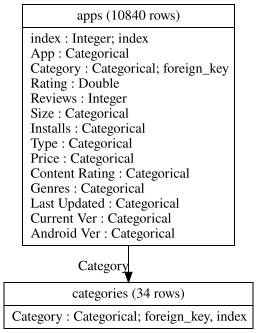

In [ ]:
es.plot()

In [ ]:
# 5. Realiza la síntesis profunda de características (DFS) con la entidad creada
# (categories) como objetivo

feature_matrix, dfs_features = ft.dfs(
    entityset = es,target_dataframe_name = 'categories')

/usr/local/lib/python3.13/dist-packages/featuretools/computational_backends/feature_set_calculator.py:785: FutureWarning: The provided callable <function min at 0x7c176ad69b20> is currently using SeriesGroupBy.min. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "min" instead.
  ).agg(to_agg)
/usr/local/lib/python3.13/dist-packages/featuretools/computational_backends/feature_set_calculator.py:785: FutureWarning: The provided callable <function sum at 0x7c176ad68fe0> is currently using SeriesGroupBy.sum. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "sum" instead.
  ).agg(to_agg)
/usr/local/lib/python3.13/dist-packages/featuretools/computational_backends/feature_set_calculator.py:785: FutureWarning: The provided callable <function max at 0x7c176ad699e0> is currently using SeriesGroupBy.max. In a future version of pandas, the provided callable will b

In [ ]:
feature_matrix

,COUNT(apps),MAX(apps.Rating),MAX(apps.Reviews),MEAN(apps.Rating),MEAN(apps.Reviews),MIN(apps.Rating),MIN(apps.Reviews),MODE(apps.Android Ver),MODE(apps.App),MODE(apps.Content Rating),...,NUM_UNIQUE(apps.Last Updated),NUM_UNIQUE(apps.Price),NUM_UNIQUE(apps.Size),NUM_UNIQUE(apps.Type),SKEW(apps.Rating),SKEW(apps.Reviews),STD(apps.Rating),STD(apps.Reviews),SUM(apps.Rating),SUM(apps.Reviews)
Category,,,,,,,,,,,,,,,,,,,,,
ART_AND_DESIGN,65,5.0,295237.0,4.358065,2.637600e+04,3.2,0.0,4.1 and up,Textgram - write on photos,Everyone,...,52,2,48,2,-0.796318,2.940354,0.358297,6.932801e+04,270.2,1.714440e+06
AUTO_AND_VEHICLES,85,4.9,271920.0,4.190411,1.369019e+04,2.1,0.0,4.0 and up,AE Garage,Everyone,...,55,4,57,2,-1.382970,4.436712,0.543692,4.340611e+04,305.9,1.163666e+06
BEAUTY,53,4.9,113715.0,4.278571,7.476226e+03,3.1,0.0,4.0.3 and up,AI Face Beauty Analysis - IntelliFace (Free),Everyone,...,48,1,37,1,-0.698343,3.965378,0.362603,1.909467e+04,179.7,3.962400e+05
BOOKS_AND_REFERENCE,231,5.0,2915189.0,4.346067,9.506090e+04,2.7,0.0,4.0 and up,Amazon Kindle,Everyone,...,180,14,105,2,-1.155845,6.208787,0.429046,3.532053e+05,773.6,2.195907e+07
BUSINESS,460,5.0,1279800.0,4.121452,3.033598e+04,1.0,0.0,4.1 and up,Box,Everyone,...,263,11,139,2,-1.446071,7.059731,0.624422,1.418051e+05,1248.8,1.395455e+07
COMICS,60,5.0,1013944.0,4.155172,5.638793e+04,2.8,1.0,4.0.3 and up,DC Comics,Everyone,...,39,1,41,1,-0.757151,4.398250,0.537758,1.958715e+05,241.0,3.383276e+06
COMMUNICATION,387,5.0,69119316.0,4.158537,2.107138e+06,1.0,0.0,Varies with device,Viber Messenger,Everyone,...,200,10,118,2,-2.497412,6.685781,0.426192,8.189705e+06,1364.0,8.154623e+08
DATING,234,5.0,516917.0,3.970769,3.115931e+04,1.0,0.0,4.0.3 and up,Adult Dirty Emojis,Mature 17+,...,69,6,81,2,-1.376258,3.501138,0.630510,8.238692e+04,774.3,7.291278e+06
EDUCATION,156,4.9,6290507.0,4.389032,2.538191e+05,3.5,11.0,Varies with device,Duolingo: Learn Languages Free,Everyone,...,80,3,57,2,-0.521607,5.760850,0.251894,9.997874e+05,680.3,3.959579e+07


In [ ]:
# Para obtener el conteo de columnas en la matriz de características:

len(feature_matrix.columns)

33

In [ ]:
# 6. Aplica las funciones definidas por Featuretools para la selección de características:
  # • selection.remove_highly_null_features()
  # • selection.remove_single_value_features()
  # • selection.remove_highly_correlated_features()

new_matrix, features = ft.selection.remove_highly_null_features(
    feature_matrix, features=dfs_features)

new_matrix, features = ft.selection.remove_single_value_features(
    new_matrix, features = features)

new_matrix, features = ft.selection.remove_highly_correlated_features(
    new_matrix, features = features)

/usr/local/lib/python3.13/dist-packages/woodwork/type_sys/utils.py:33: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  pd.to_datetime(
/usr/local/lib/python3.13/dist-packages/woodwork/type_sys/utils.py:33: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  pd.to_datetime(
/usr/local/lib/python3.13/dist-packages/woodwork/type_sys/utils.py:33: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  pd.to_datetime(
/usr/local/lib/python3.13/dist-packages/woodwork/type_sys/utils.py:33: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. 

In [ ]:
len(new_matrix.columns)

24

In [ ]:
# 7. Con las dimensiones de la matriz resultante determina el número de
# características eliminadas y visualiza cuáles fueron.

# Volvemos a calcular temporalmente el DFS original para recuperar las 33 columnas originales
feature_matrix_original, _ = ft.dfs(entityset=es, target_dataframe_name='categories')

# Encontramos las columnas eliminadas haciendo la diferencia de conjuntos
columnas_originales = set(feature_matrix_original.columns)
columnas_filtradas = set(new_matrix.columns)
columnas_eliminadas = columnas_originales - columnas_filtradas


Columnas eliminadas: {'NUM_UNIQUE(apps.App)', 'STD(apps.Reviews)', 'MEAN(apps.Rating)', 'MIN(apps.Rating)', 'NUM_UNIQUE(apps.Last Updated)', 'MODE(apps.Type)', 'SUM(apps.Rating)', 'NUM_UNIQUE(apps.Current Ver)', 'MIN(apps.Reviews)'}


/usr/local/lib/python3.13/dist-packages/featuretools/computational_backends/feature_set_calculator.py:785: FutureWarning: The provided callable <function min at 0x7c176ad69b20> is currently using SeriesGroupBy.min. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "min" instead.
  ).agg(to_agg)
/usr/local/lib/python3.13/dist-packages/featuretools/computational_backends/feature_set_calculator.py:785: FutureWarning: The provided callable <function sum at 0x7c176ad68fe0> is currently using SeriesGroupBy.sum. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "sum" instead.
  ).agg(to_agg)
/usr/local/lib/python3.13/dist-packages/featuretools/computational_backends/feature_set_calculator.py:785: FutureWarning: The provided callable <function max at 0x7c176ad699e0> is currently using SeriesGroupBy.max. In a future version of pandas, the provided callable will b

In [ ]:
# Mostramos las columnas eliminadas de forma correcta y limpia
print("Columnas eliminadas:", (columnas_eliminadas))

Columnas eliminadas: {'NUM_UNIQUE(apps.App)', 'STD(apps.Reviews)', 'MEAN(apps.Rating)', 'MIN(apps.Rating)', 'NUM_UNIQUE(apps.Last Updated)', 'MODE(apps.Type)', 'SUM(apps.Rating)', 'NUM_UNIQUE(apps.Current Ver)', 'MIN(apps.Reviews)'}
